# Detection of Suspicious Card Transactions Using Classical Machine Learning and Neural Network Approaches


### Research Question

Using publicly available anonymized transaction data, how effectively can classical machine learning and neural network approaches identify suspicious card transactions in a highly imbalanced binary classification problem?

### Purpose of This Notebook

This notebook supports the initial capstone submission by documenting the acquired dataset, verifying data quality, examining the target-label distribution, summarizing the available input variables, and creating data-understanding visualizations.

The dataset is used as a public-data proxy for studying suspicious financial transaction detection in organizational oversight applications. It is not represented as a Department of Defense transaction dataset.

In [1]:
!pip install -q -U "scikit-learn>=1.7"

import sklearn; print(sklearn.__version__)

1.9.1


In [2]:


from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_PATH = Path("dataset_creditcard.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "The file dataset_creditcard.csv was not found. "
        "Place it in the same folder as this notebook."
    )

df = pd.read_csv(DATA_PATH)

df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 1. Data Acquisition

The dataset was obtained from the publicly available *Credit Card Fraud Detection* dataset hosted on Kaggle by the Machine Learning Group of the Université Libre de Bruxelles. It contains anonymized credit card transactions completed by European cardholders over approximately two days in September 2013.

The output variable is $\texttt{Class}$, where

$$
\mathrm{Class} =
\begin{cases}
0, & \mathrm{legitimate\ transaction}, \\
1, & \mathrm{fraudulent\ transaction}.
\end{cases}
$$

The available input variables are $\texttt{Time}$, $\texttt{Amount}$, and $28$ anonymized numerical variables identified as $\texttt{V1}$ through $\texttt{V28}$. The variables $\texttt{V1}$--$\texttt{V28}$ were transformed using principal component analysis (PCA) to preserve confidentiality. Consequently, they may support prediction, but their original operational meanings cannot be interpreted.

The variable $\texttt{Time}$ records the number of seconds elapsed since the first transaction in the dataset. It is not a calendar-date variable. The variable $\texttt{Amount}$ records the value of each transaction.

In [3]:
n_rows, n_columns = df.shape
feature_columns = [column for column in df.columns if column != "Class"]
n_features = len(feature_columns)

dataset_structure = pd.DataFrame(
    {
        "Attribute": [
            "Number of observations",
            "Number of input features",
            "Number of output variables",
            "Output variable",
            "Problem type"
        ],
        "Value": [
            f"{n_rows:,}",
            n_features,
            1,
            "Class",
            "Binary classification"
        ]
    }
)

display(dataset_structure)

print("Dataset columns:")
print(df.columns.tolist())

print("\nVariable data types:")
display(df.dtypes.value_counts().rename_axis("Data Type").reset_index(name="Count"))

,Attribute,Value
0,Number of observations,"284,807"
1,Number of input features,30
2,Number of output variables,1
3,Output variable,Class
4,Problem type,Binary classification


Dataset columns:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Variable data types:


,Data Type,Count
0,float64,30
1,int64,1


## 2. Modeling Summary

The capstone project addresses a supervised binary classification problem. The target is the identification of fraudulent card transactions among a much larger number of legitimate transactions. At this stage, no predictive model is trained; the purpose is to establish the modeling objective and understand the acquired data.

In [4]:
modeling_summary = pd.DataFrame(
    {
        "Attribute": [
            "Problem type",
            "Label description",
            "Label variable name in the dataset",
            "Number of features in dataset",
            "Number of datapoints",
            "Hypothesis on which features will be most influential",
            "Success criteria"
        ],
        "This Work": [
            "Binary classification",
            "Whether a card transaction is fraudulent or legitimate",
            "Class",
            f"{n_features} input features",
            f"{n_rows:,} transactions",
            (
                "Transaction amount and selected anonymized PCA components "
                "may help distinguish fraudulent from legitimate transactions; "
                "however, the original meanings of the PCA components are unavailable."
            ),
            (
                "Effective identification of fraudulent transactions under severe "
                "class imbalance, evaluated later using precision-recall based measures, "
                "recall, precision, F1-score, and confusion matrices rather than accuracy alone."
            )
        ]
    }
)

display(modeling_summary)

,Attribute,This Work
0,Problem type,Binary classification
1,Label description,Whether a card transaction is fraudulent or le...
2,Label variable name in the dataset,Class
3,Number of features in dataset,30 input features
4,Number of datapoints,"284,807 transactions"
5,Hypothesis on which features will be most infl...,Transaction amount and selected anonymized PCA...
6,Success criteria,Effective identification of fraudulent transac...


## 3. Data Quality Assessment

Initial data-quality checks are necessary before conducting descriptive analysis or developing predictive models. This assessment evaluates missing values, exact duplicate observations, and the general structure of the acquired dataset.

Exact duplicate records are identified in this notebook but are not removed at this stage. Any decision to remove observations should be justified during the later modeling phase because removing records could affect class distribution and model evaluation.

In [5]:
missing_values = df.isna().sum()
total_missing_values = int(missing_values.sum())
columns_with_missing_values = int((missing_values > 0).sum())
duplicate_rows = int(df.duplicated().sum())

data_quality_summary = pd.DataFrame(
    {
        "Data Quality Check": [
            "Total missing values",
            "Columns containing missing values",
            "Exact duplicate rows"
        ],
        "Result": [
            f"{total_missing_values:,}",
            columns_with_missing_values,
            f"{duplicate_rows:,}"
        ]
    }
)

display(data_quality_summary)

if total_missing_values > 0:
    display(
        missing_values[missing_values > 0]
        .sort_values(ascending=False)
        .rename("Missing Values")
        .to_frame()
    )

,Data Quality Check,Result
0,Total missing values,0
1,Columns containing missing values,0
2,Exact duplicate rows,"1,081"


## 4. Output Variable Understanding

The variable $\texttt{Class}$ is the binary output variable used to distinguish legitimate transactions from fraudulent transactions. Fraud detection commonly involves substantial class imbalance because fraudulent transactions occur much less frequently than legitimate transactions.

Class imbalance is important for the later modeling stages because a model could obtain high overall accuracy by predicting most or all transactions as legitimate. Therefore, the distribution of the output variable must be examined before predictive modeling begins.

In [6]:
class_distribution = (
    df["Class"]
    .value_counts()
    .sort_index()
    .rename(index={0: "Legitimate", 1: "Fraudulent"})
    .rename("Number of Transactions")
    .to_frame()
)

class_distribution["Percentage"] = (
    100 * class_distribution["Number of Transactions"] / len(df)
).round(4)

display(class_distribution)

fraud_count = int((df["Class"] == 1).sum())
fraud_percentage = 100 * fraud_count / len(df)

print(f"Fraudulent transactions: {fraud_count:,}")
print(f"Fraudulent transaction percentage: {fraud_percentage:.4f}%")

,Number of Transactions,Percentage
Class,,
Legitimate,284315,99.8273
Fraudulent,492,0.1727


Fraudulent transactions: 492
Fraudulent transaction percentage: 0.1727%


### Figure 1. Distribution of Legitimate and Fraudulent Transactions

The target-label distribution is visualized to determine the extent of class imbalance. A logarithmic vertical axis is used so that the minority fraudulent class remains visible beside the much larger legitimate class.

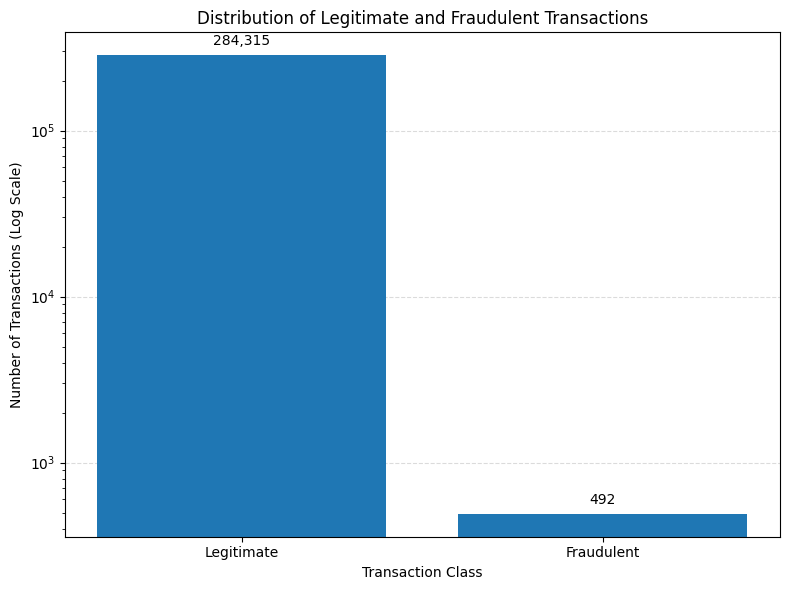

In [7]:
fig, ax = plt.subplots(figsize=(8,6))

bars = ax.bar(
    class_distribution.index,
    class_distribution["Number of Transactions"]
)

ax.set_yscale("log")
ax.set_title("Distribution of Legitimate and Fraudulent Transactions")
ax.set_xlabel("Transaction Class")
ax.set_ylabel("Number of Transactions (Log Scale)")
ax.grid(axis="y", color="lightgray", linestyle="--", linewidth=0.8, alpha=0.8)
ax.set_axisbelow(True)

for bar, value in zip(bars, class_distribution["Number of Transactions"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value * 1.10,
        f"{value:,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig("figure_1_class_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

Fig. 1. Distribution of legitimate and fraudulent transactions in the acquired dataset. The logarithmic scale is used to display the severely underrepresented fraudulent class. Data derived from the publicly available Credit Card Fraud Detection dataset.

## 5. Input Variable Understanding

The dataset includes two directly interpretable numerical variables: $\texttt{Time}$ and $\texttt{Amount}$. The remaining input variables, $\texttt{V1}$ through $\texttt{V28}$, are anonymized PCA-transformed features.

For interpretability, $\texttt{Time}$ is converted from elapsed seconds to elapsed hours:

$$
\texttt{ElapsedHour} = \frac{\texttt{Time}}{3600}
$$

This derived variable is used only for descriptive visualization in the current notebook. It does not represent a calendar date or a specific time of day.

In [8]:
df["ElapsedHour"] = df["Time"] / 3600

amount_summary = (
    df.groupby("Class")["Amount"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .rename(index={0: "Legitimate", 1: "Fraudulent"})
    .round(2)
)

elapsed_time_summary = pd.DataFrame(
    {
        "Measure": [
            "Minimum elapsed hour",
            "Maximum elapsed hour",
            "Observed time span in hours"
        ],
        "Value": [
            df["ElapsedHour"].min(),
            df["ElapsedHour"].max(),
            df["ElapsedHour"].max() - df["ElapsedHour"].min()
        ]
    }
).round(2)

print("Transaction Amount Summary by Class")
display(amount_summary)

print("Elapsed Time Summary")
display(elapsed_time_summary)

Transaction Amount Summary by Class


,count,mean,median,std,min,max
Class,,,,,,
Legitimate,284315,88.29,22.00,250.11,0.0,25691.16
Fraudulent,492,122.21,9.25,256.68,0.0,2125.87


Elapsed Time Summary


,Measure,Value
0,Minimum elapsed hour,0.0
1,Maximum elapsed hour,48.0
2,Observed time span in hours,48.0


### Figure 2. Transaction Amount by Class

Transaction values are examined by output class to determine whether fraudulent and legitimate observations show different amount patterns. Because transaction amounts are strongly right-skewed, the visualization uses the transformation

$$
\log(1 + \texttt{Amount})
$$

for display purposes only. The original $\texttt{Amount}$ variable remains unchanged in the acquired dataset.

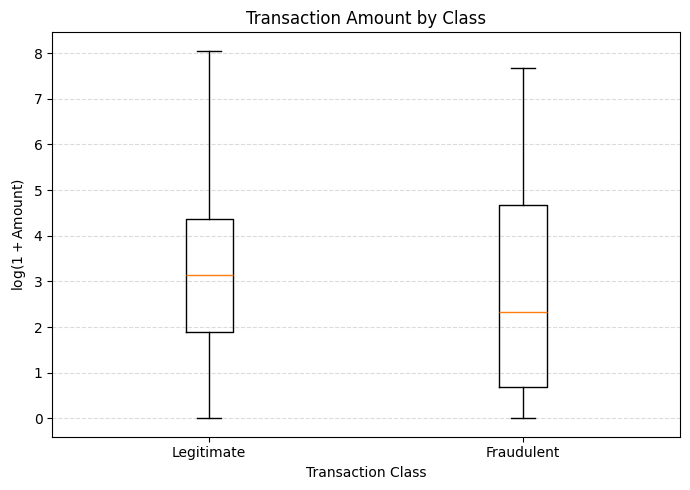

In [9]:
legitimate_amounts = np.log1p(df.loc[df["Class"] == 0, "Amount"])
fraudulent_amounts = np.log1p(df.loc[df["Class"] == 1, "Amount"])

fig, ax = plt.subplots(figsize=(7, 5))

ax.boxplot(
    [legitimate_amounts, fraudulent_amounts],
    tick_labels=["Legitimate", "Fraudulent"],
    showfliers=False
)

ax.set_title("Transaction Amount by Class")
ax.set_xlabel("Transaction Class")
ax.set_ylabel(r"$\log(1 + \mathrm{Amount})$")
ax.grid(axis="y", color="lightgray", linestyle="--", linewidth=0.8, alpha=0.8)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("figure_2_amount_by_class.png", dpi=300, bbox_inches="tight")
plt.show()

Fig. 2. Comparison of transaction amounts for legitimate and fraudulent observations. A $\log(1+\texttt{Amount})$ transformation is applied for visualization because transaction values are right-skewed. Data derived from the publicly available Credit Card Fraud Detection dataset.

### Figure 3. Fraudulent Transactions Across Elapsed Time

The temporal distribution of fraudulent observations is examined using elapsed hours since the first recorded transaction. This descriptive analysis helps determine whether fraudulent cases appear across the observation period or are concentrated in selected intervals.

The variable used in this visualization represents elapsed time only and should not be interpreted as a calendar date.

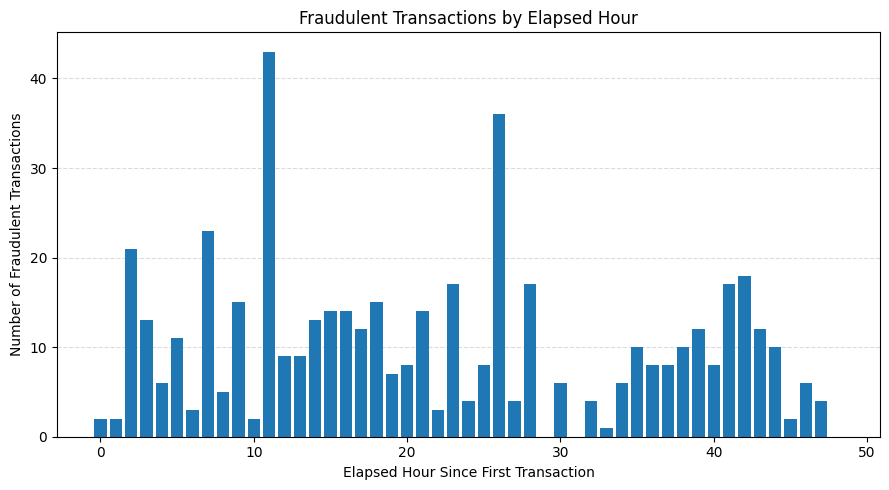

In [10]:
fraudulent_transactions = df.loc[df["Class"] == 1].copy()

fraudulent_transactions["ElapsedHourBin"] = np.floor(
    fraudulent_transactions["ElapsedHour"]
).astype(int)

hourly_fraud_counts = (
    fraudulent_transactions
    .groupby("ElapsedHourBin")
    .size()
    .reindex(
        range(0, int(np.ceil(df["ElapsedHour"].max())) + 1),
        fill_value=0
    )
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(hourly_fraud_counts.index, hourly_fraud_counts.values)

ax.set_title("Fraudulent Transactions by Elapsed Hour")
ax.set_xlabel("Elapsed Hour Since First Transaction")
ax.set_ylabel("Number of Fraudulent Transactions")
ax.grid(axis="y", color="lightgray", linestyle="--", linewidth=0.8, alpha=0.8)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("figure_3_fraud_by_elapsed_hour.png", dpi=300, bbox_inches="tight")
plt.show()

Fig. 3. Distribution of fraudulent transactions across elapsed hours since the first recorded transaction. The elapsed-time variable does not represent calendar dates. Data derived from the publicly available Credit Card Fraud Detection dataset.

## 6. Feature Summary

In [11]:
feature_summary = pd.DataFrame(
    {
        "Variable": [
            "Time",
            "Amount",
            "V1--V28",
            "Class"
        ],
        "Role": [
            "Input",
            "Input",
            "Input",
            "Output"
        ],
        "Description": [
            "Seconds elapsed since the first transaction",
            "Transaction monetary value",
            "Anonymized PCA-transformed numerical features",
            "Transaction status: 0 = legitimate, 1 = fraudulent"
        ],
        "Data Understanding Result": [
            f"Numerical; spans approximately {df['ElapsedHour'].max():.2f} elapsed hours",
            (
                f"Numerical and right-skewed; median = {df['Amount'].median():.2f}, "
                f"maximum = {df['Amount'].max():,.2f}"
            ),
            "Twenty-eight numerical transformed variables",
            f"Binary and severely imbalanced; fraudulent transactions = {fraud_percentage:.4f}%"
        ]
    }
)

display(feature_summary)

,Variable,Role,Description,Data Understanding Result
0,Time,Input,Seconds elapsed since the first transaction,Numerical; spans approximately 48.00 elapsed h...
1,Amount,Input,Transaction monetary value,"Numerical and right-skewed; median = 22.00, ma..."
2,V1--V28,Input,Anonymized PCA-transformed numerical features,Twenty-eight numerical transformed variables
3,Class,Output,"Transaction status: 0 = legitimate, 1 = fraudu...",Binary and severely imbalanced; fraudulent tra...


## 7. Initial Data Understanding Findings

The acquired dataset contains $284{,}807$ transaction observations and $30$ input features. The binary output variable, $\texttt{Class}$, identifies $492$ observations as fraudulent, representing approximately $0.1727\%$ of all recorded transactions. This distribution confirms that the proposed project involves a severely imbalanced classification problem.

No missing values were identified in the acquired file. Exact duplicate observations are reported during the initial quality assessment but are not removed during this descriptive stage. Any decision to remove duplicate records will be evaluated and justified during subsequent modeling work.

The directly interpretable numerical inputs are $\texttt{Time}$ and $\texttt{Amount}$. The $\texttt{Time}$ variable records elapsed seconds rather than a calendar date and spans approximately $48$ hours. The $\texttt{Amount}$ variable exhibits a right-skewed distribution, which motivates the logarithmic transformation used only for visualization. The remaining $28$ input variables are anonymized PCA-transformed numerical features. Although these features may support predictive performance, their operational meanings are not available for domain-level interpretation.

The severe underrepresentation of fraudulent transactions will require careful evaluation in later capstone phases. In particular, overall accuracy will not be treated as the primary measure of model quality because a majority-class prediction strategy could achieve very high accuracy while failing to detect fraud. Later model comparisons will instead emphasize precision-recall based performance, recall, precision, $F_1$-score, and confusion-matrix results.

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

X = df.drop(columns=["Class"])
y = df["Class"]

X_temp, X_test, y_temp, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=0.25,
    stratify=y_temp,
    random_state=42
)

split_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Test"],
    "Observations": [len(y_train), len(y_val), len(y_test)],
    "Fraud Cases": [y_train.sum(), y_val.sum(), y_test.sum()],
    "Fraud Percentage": [
        100 * y_train.mean(),
        100 * y_val.mean(),
        100 * y_test.mean()
    ]
})

display(split_summary)

,Dataset,Observations,Fraud Cases,Fraud Percentage
0,Training,170883,295,0.172633
1,Validation,56962,99,0.173800
2,Test,56962,98,0.172045


In [13]:
def evaluate_classifier(model_name, model, X_eval, y_eval):
    y_pred = model.predict(X_eval)

    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_eval)[:, 1]
    elif hasattr(model, "decision_function"):
        y_score = model.decision_function(X_eval)
    else:
        y_score = y_pred

    tn, fp, fn, tp = confusion_matrix(y_eval, y_pred).ravel()

    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_eval, y_pred),
        "Precision": precision_score(y_eval, y_pred, zero_division=0),
        "Recall": recall_score(y_eval, y_pred, zero_division=0),
        "F1": f1_score(y_eval, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_eval, y_score),
        "PR-AUC": average_precision_score(y_eval, y_score),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    }

In [14]:
trivial_model = DummyClassifier(strategy="most_frequent")

trivial_model.fit(X_train, y_train)

trivial_results = evaluate_classifier(
    "Trivial majority-class classifier",
    trivial_model,
    X_val,
    y_val
)

pd.DataFrame([trivial_results]).round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,TN,FP,FN,TP
0,Trivial majority-class classifier,0.9983,0.0,0.0,0.0,0.5,0.0017,56863,0,99,0


In [15]:
# Classical models
classical_models = []

logistic_balanced = Pipeline([
    ("scaler", RobustScaler()),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        solver="lbfgs",
        random_state=42
    ))
])

random_forest_balanced = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

logistic_balanced.fit(X_train, y_train)
random_forest_balanced.fit(X_train, y_train)

classical_models.append(
    evaluate_classifier(
        "Logistic Regression with class_weight",
        logistic_balanced,
        X_val,
        y_val
    )
)

classical_models.append(
    evaluate_classifier(
        "Random Forest with class_weight",
        random_forest_balanced,
        X_val,
        y_val
    )
)

classical_results = pd.DataFrame(classical_models).sort_values(
    by="F1",
    ascending=False
)

display(classical_results.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,TN,FP,FN,TP
1,Random Forest with class_weight,0.9994,0.8621,0.7576,0.8065,0.9706,0.7718,56851,12,24,75
0,Logistic Regression with class_weight,0.9751,0.0595,0.8990,0.1116,0.9747,0.6794,55456,1407,10,89


In [16]:
# Code: neural network
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

neural_network = Pipeline([
    ("scaler", RobustScaler()),
    ("model", MLPClassifier(
        hidden_layer_sizes=(16, 8),
        activation="relu",
        solver="adam",
        max_iter=30,
        early_stopping=True,
        validation_fraction=0.10,
        n_iter_no_change=5,
        batch_size=2048,
        learning_rate_init=0.001,
        random_state=42
    ))
])

neural_network.fit(
    X_train,
    y_train,
    model__sample_weight=sample_weights
)

nn_results = evaluate_classifier(
    "MLP Neural Network with class weights",
    neural_network,
    X_val,
    y_val
)

pd.DataFrame([nn_results]).round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,TN,FP,FN,TP
0,MLP Neural Network with class weights,0.9783,0.0637,0.8384,0.1185,0.9646,0.6536,55644,1219,16,83


In [17]:
# Validation summary
validation_summary = pd.DataFrame(
    [trivial_results] + classical_models + [nn_results]
).sort_values(
    by="F1",
    ascending=False
)

display(validation_summary.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,TN,FP,FN,TP
2,Random Forest with class_weight,0.9994,0.8621,0.7576,0.8065,0.9706,0.7718,56851,12,24,75
3,MLP Neural Network with class weights,0.9783,0.0637,0.8384,0.1185,0.9646,0.6536,55644,1219,16,83
1,Logistic Regression with class_weight,0.9751,0.0595,0.8990,0.1116,0.9747,0.6794,55456,1407,10,89
0,Trivial majority-class classifier,0.9983,0.0000,0.0000,0.0000,0.5000,0.0017,56863,0,99,0


## 9. Classical Model Feature Importance

The Random Forest model produced the strongest validation F1-score among the classical models. Feature importance values are extracted from the fitted Random Forest model to provide an initial view of which input variables contributed most to the classical model.

In [18]:
rf_feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": random_forest_balanced.feature_importances_
}).sort_values(by="Importance", ascending=False)

display(rf_feature_importance.head(10).round(4))

,Feature,Importance
14,V14,0.1911
10,V10,0.1412
12,V12,0.1007
11,V11,0.0878
4,V4,0.0826
17,V17,0.0723
3,V3,0.0544
16,V16,0.0293
7,V7,0.0284
2,V2,0.0258


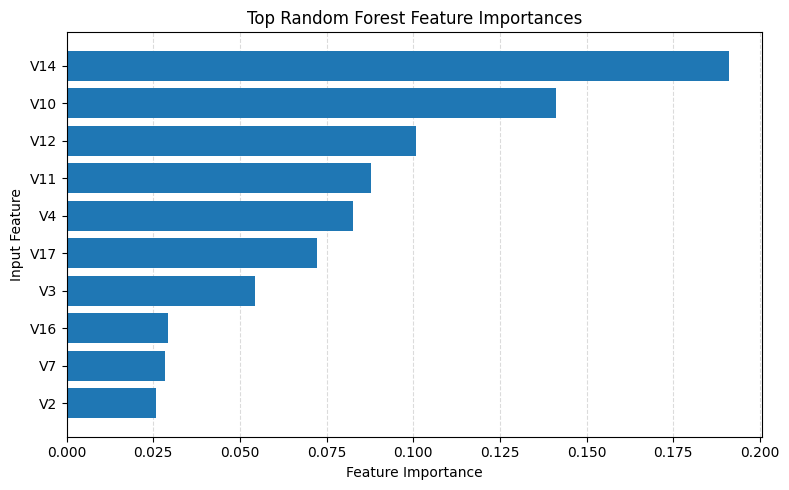

In [19]:
top_n = 10
top_features = rf_feature_importance.head(top_n).sort_values(
    by="Importance",
    ascending=True
)

fig, ax = plt.subplots(figsize=(8, 5))

ax.barh(top_features["Feature"], top_features["Importance"])

ax.set_title("Top Random Forest Feature Importances")
ax.set_xlabel("Feature Importance")
ax.set_ylabel("Input Feature")
ax.grid(axis="x", color="lightgray", linestyle="--", linewidth=0.8, alpha=0.8)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("figure_4_random_forest_feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

## 10. Neural Network Hyperparameter Sweep

A small neural-network hyperparameter sweep was performed using the validation set. The sweep compared three hidden-layer architectures while keeping the solver, early stopping, scaling method, and class weighting approach consistent.

In [20]:
mlp_architectures = [
    (8,),
    (16, 8),
    (32, 16)
]

nn_sweep_results = []

for architecture in mlp_architectures:
    model = Pipeline([
        ("scaler", RobustScaler()),
        ("model", MLPClassifier(
            hidden_layer_sizes=architecture,
            activation="relu",
            solver="adam",
            alpha=0.0001,
            max_iter=30,
            early_stopping=True,
            validation_fraction=0.10,
            n_iter_no_change=5,
            batch_size=2048,
            learning_rate_init=0.001,
            random_state=42
        ))
    ])

    model.fit(
        X_train,
        y_train,
        model__sample_weight=sample_weights
    )

    result = evaluate_classifier(
        f"MLP {architecture}",
        model,
        X_val,
        y_val
    )

    nn_sweep_results.append(result)

nn_sweep_summary = pd.DataFrame(nn_sweep_results).sort_values(
    by="F1",
    ascending=False
)

display(nn_sweep_summary.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,TN,FP,FN,TP
2,"MLP (32, 16)",0.9871,0.1047,0.8485,0.1865,0.9555,0.6867,56145,718,15,84
1,"MLP (16, 8)",0.9783,0.0637,0.8384,0.1185,0.9646,0.6536,55644,1219,16,83
0,"MLP (8,)",0.9709,0.0496,0.8687,0.0939,0.9446,0.6874,55216,1647,13,86


## 11. Classical Modeling Results Table

The following table summarizes the validation-set results for the trivial classifier and classical machine learning models. 

In [21]:
classical_results_for_paper = pd.DataFrame(
    [trivial_results] + classical_models
)

classical_results_for_paper = classical_results_for_paper[
    [
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC",
        "PR-AUC",
        "TN",
        "FP",
        "FN",
        "TP"
    ]
].sort_values(by="F1", ascending=False)

display(classical_results_for_paper.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,TN,FP,FN,TP
2,Random Forest with class_weight,0.9994,0.8621,0.7576,0.8065,0.9706,0.7718,56851,12,24,75
1,Logistic Regression with class_weight,0.9751,0.0595,0.8990,0.1116,0.9747,0.6794,55456,1407,10,89
0,Trivial majority-class classifier,0.9983,0.0000,0.0000,0.0000,0.5000,0.0017,56863,0,99,0


## 12. Neural Network Regularization Sweep

The best neural-network architecture from the hidden-layer sweep was MLP (32, 16). To evaluate one regularization technique, the L2 regularization parameter `alpha` was varied while keeping the architecture and other training settings constant.

In [22]:
alpha_values = [0.0001, 0.001, 0.01, 0.1]

nn_regularization_results = []

for alpha_value in alpha_values:
    model = Pipeline([
        ("scaler", RobustScaler()),
        ("model", MLPClassifier(
            hidden_layer_sizes=(32, 16),
            activation="relu",
            solver="adam",
            alpha=alpha_value,
            max_iter=30,
            early_stopping=True,
            validation_fraction=0.10,
            n_iter_no_change=5,
            batch_size=2048,
            learning_rate_init=0.001,
            random_state=42
        ))
    ])

    model.fit(
        X_train,
        y_train,
        model__sample_weight=sample_weights
    )

    result = evaluate_classifier(
        f"MLP (32, 16), alpha={alpha_value}",
        model,
        X_val,
        y_val
    )

    result["Alpha"] = alpha_value
    nn_regularization_results.append(result)

nn_regularization_summary = pd.DataFrame(nn_regularization_results).sort_values(
    by="F1",
    ascending=False
)

display(nn_regularization_summary.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,TN,FP,FN,TP,Alpha
2,"MLP (32, 16), alpha=0.01",0.9871,0.1049,0.8485,0.1867,0.9555,0.6875,56146,717,15,84,0.0100
0,"MLP (32, 16), alpha=0.0001",0.9871,0.1047,0.8485,0.1865,0.9555,0.6867,56145,718,15,84,0.0001
1,"MLP (32, 16), alpha=0.001",0.9871,0.1046,0.8485,0.1863,0.9555,0.6872,56144,719,15,84,0.0010
3,"MLP (32, 16), alpha=0.1",0.9870,0.1037,0.8485,0.1848,0.9557,0.6879,56137,726,15,84,0.1000


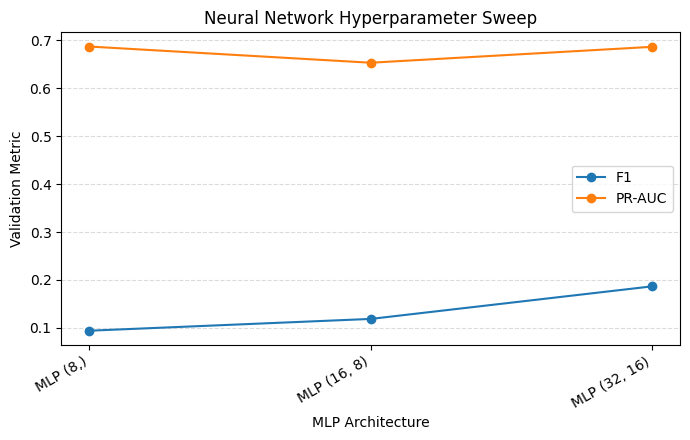

In [23]:
nn_sweep_plot = nn_sweep_summary.copy()

fig, ax = plt.subplots(figsize=(7, 4.5))

architecture_order = [
    "MLP (8,)",
    "MLP (16, 8)",
    "MLP (32, 16)"
]


nn_sweep_plot["Model"] = pd.Categorical(
    nn_sweep_plot["Model"],
    categories=architecture_order,
    ordered=True
)

nn_sweep_plot = nn_sweep_plot.sort_values("Model")

ax.plot(
    nn_sweep_plot["Model"],
    nn_sweep_plot["F1"],
    marker="o",
    label="F1"
)

ax.plot(
    nn_sweep_plot["Model"],
    nn_sweep_plot["PR-AUC"],
    marker="o",
    label="PR-AUC"
)

ax.set_title("Neural Network Hyperparameter Sweep")
ax.set_xlabel("MLP Architecture")
ax.set_ylabel("Validation Metric")
ax.grid(axis="y", color="lightgray", linestyle="--", linewidth=0.8, alpha=0.8)
ax.set_axisbelow(True)
ax.legend()

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("figure_5_nn_hyperparameter_sweep.png", dpi=300, bbox_inches="tight")
plt.show()

In [24]:
nn_baseline = nn_sweep_summary.loc[
    nn_sweep_summary["Model"] == "MLP (8,)"
].iloc[0].to_dict()

nn_best_sweep = nn_sweep_summary.loc[
    nn_sweep_summary["Model"] == "MLP (32, 16)"
].iloc[0].to_dict()

nn_best_regularized = nn_regularization_summary.iloc[0].to_dict()

nn_results_for_paper = pd.DataFrame([
    nn_baseline,
    nn_best_sweep,
    nn_best_regularized,
    trivial_results
])

nn_results_for_paper["Model"] = [
    "Baseline NN: MLP (8,)",
    "After hyperparameter sweep: MLP (32, 16)",
    f"After regularization: MLP (32, 16), alpha={nn_best_regularized['Alpha']}",
    "Trivial majority-class classifier"
]

nn_results_for_paper = nn_results_for_paper[
    [
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC",
        "PR-AUC",
        "TN",
        "FP",
        "FN",
        "TP"
    ]
]

display(nn_results_for_paper.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,TN,FP,FN,TP
0,"Baseline NN: MLP (8,)",0.9709,0.0496,0.8687,0.0939,0.9446,0.6874,55216,1647,13,86
1,"After hyperparameter sweep: MLP (32, 16)",0.9871,0.1047,0.8485,0.1865,0.9555,0.6867,56145,718,15,84
2,"After regularization: MLP (32, 16), alpha=0.01",0.9871,0.1049,0.8485,0.1867,0.9555,0.6875,56146,717,15,84
3,Trivial majority-class classifier,0.9983,0.0000,0.0000,0.0000,0.5000,0.0017,56863,0,99,0


## 13. Final Holdout Evaluation

In [25]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

final_models = []

# Random Forest
rf_final = Pipeline([
    ("model",
     RandomForestClassifier(
         n_estimators=300,
         class_weight="balanced",
         random_state=42,
         n_jobs=-1
     ))
])

rf_final.fit(X_train, y_train)

rf_probs = rf_final.predict_proba(X_test)[:, 1]
rf_pred = (rf_probs >= 0.5).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, rf_pred).ravel()

final_models.append({
    "Model": "Random Forest",
    "Accuracy": accuracy_score(y_test, rf_pred),
    "Precision": precision_score(y_test, rf_pred, zero_division=0),
    "Recall": recall_score(y_test, rf_pred),
    "F1": f1_score(y_test, rf_pred),
    "ROC-AUC": roc_auc_score(y_test, rf_probs),
    "PR-AUC": average_precision_score(y_test, rf_probs),
    "TN": tn,
    "FP": fp,
    "FN": fn,
    "TP": tp
})

# Neural Network
nn_final = Pipeline([
    ("scaler", RobustScaler()),
    ("model",
     MLPClassifier(
         hidden_layer_sizes=(32,16),
         alpha=0.01,
         activation="relu",
         solver="adam",
         early_stopping=True,
         validation_fraction=0.10,
         max_iter=30,
         random_state=42
     ))
])

nn_final.fit(
    X_train,
    y_train,
    model__sample_weight=sample_weights
)

nn_probs = nn_final.predict_proba(X_test)[:,1]
nn_pred = (nn_probs >= 0.5).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, nn_pred).ravel()

final_models.append({
    "Model": "Neural Network",
    "Accuracy": accuracy_score(y_test, nn_pred),
    "Precision": precision_score(y_test, nn_pred, zero_division=0),
    "Recall": recall_score(y_test, nn_pred),
    "F1": f1_score(y_test, nn_pred),
    "ROC-AUC": roc_auc_score(y_test, nn_probs),
    "PR-AUC": average_precision_score(y_test, nn_probs),
    "TN": tn,
    "FP": fp,
    "FN": fn,
    "TP": tp
})

display(pd.DataFrame(final_models).round(4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,TN,FP,FN,TP
0,Random Forest,0.9996,0.9302,0.8163,0.8696,0.9803,0.8568,56858,6,18,80
1,Neural Network,0.9908,0.1457,0.8980,0.2507,0.9617,0.7330,56348,516,10,88


## 14. Final Model Confusion Matrices

Confusion matrices were created for the final Random Forest and Neural Network models on the holdout test set. These matrices show the number of legitimate and fraudulent transactions correctly and incorrectly classified by each model.

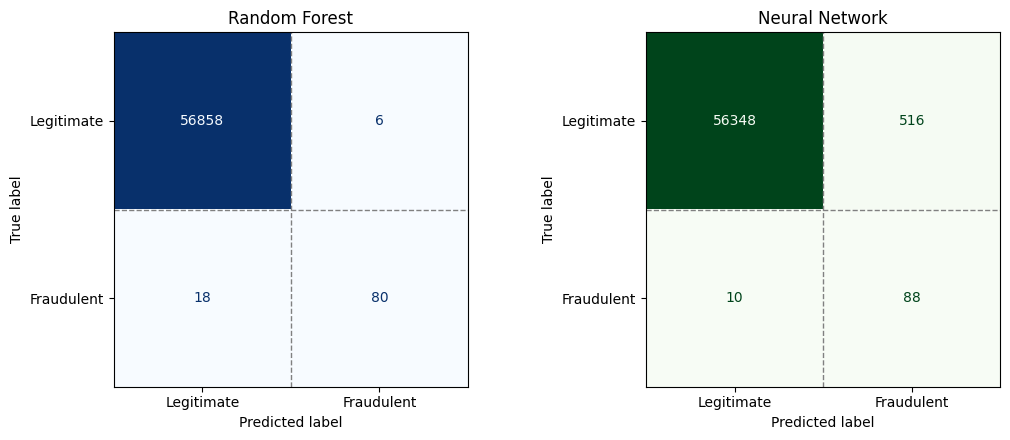

In [26]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

plots = [
    (axes[0], rf_pred, "Random Forest", "Blues"),
    (axes[1], nn_pred, "Neural Network", "Greens")
]

for ax, predictions, title, cmap in plots:
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        display_labels=["Legitimate", "Fraudulent"],
        values_format="d",
        ax=ax,
        colorbar=False,
        cmap=cmap
    )

    ax.set_title(title)

    # Add visible internal grid lines between matrix cells.
    ax.set_xticks([0.5], minor=True)
    ax.set_yticks([0.5], minor=True)
    ax.grid(which="minor", color="grey", linestyle="--", linewidth=1)

    ax.tick_params(which="minor", bottom=False, left=False)

plt.tight_layout()
plt.savefig("figure_6_final_confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()

## 15. Neural Network Overfitting Assessment

To evaluate overfitting, two neural-network configurations were compared. The first model used a larger architecture without early stopping, while the second used the selected regularized architecture with early stopping. Training loss curves were compared to determine whether the corrected model stabilized earlier.

In [27]:
# Used a scaled version of the data for direct MLP fitting.
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Overfit-prone model: larger network, no early stopping.
mlp_overfit = MLPClassifier(
    hidden_layer_sizes=(128, 64, 32),
    activation="relu",
    solver="adam",
    alpha=0.00001,
    max_iter=80,
    early_stopping=False,
    batch_size=2048,
    learning_rate_init=0.001,
    random_state=42
)

mlp_overfit.fit(
    X_train_scaled,
    y_train,
    sample_weight=sample_weights
)

# Corrected model: selected architecture, L2 regularization, early stopping.
mlp_corrected = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    activation="relu",
    solver="adam",
    alpha=0.01,
    max_iter=80,
    early_stopping=True,
    validation_fraction=0.10,
    n_iter_no_change=5,
    batch_size=2048,
    learning_rate_init=0.001,
    random_state=42
)

mlp_corrected.fit(
    X_train_scaled,
    y_train,
    sample_weight=sample_weights
)

print("Overfit-prone model iterations:", mlp_overfit.n_iter_)
print("Corrected model iterations:", mlp_corrected.n_iter_)

Overfit-prone model iterations: 72
Corrected model iterations: 18


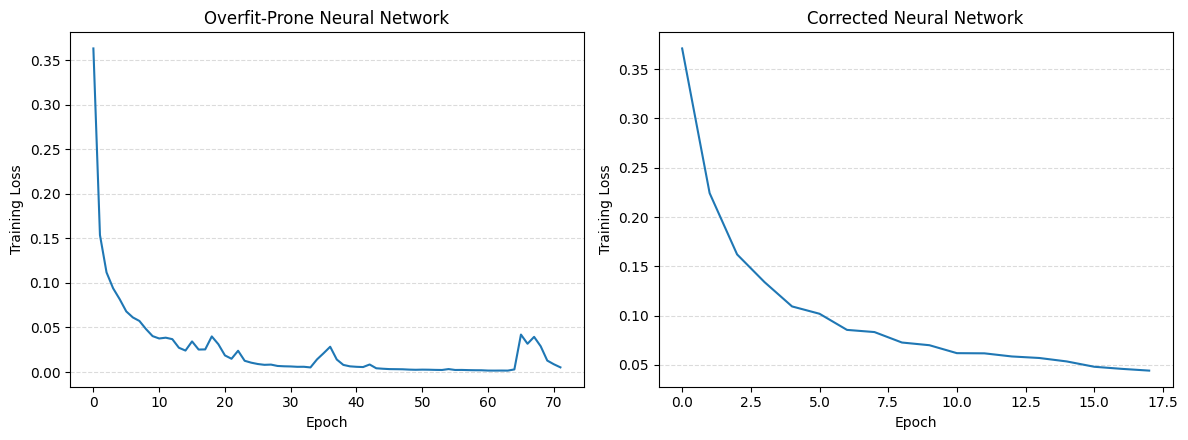

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(mlp_overfit.loss_curve_)
axes[0].set_title("Overfit-Prone Neural Network")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Training Loss")
axes[0].grid(axis="y", color="lightgray", linestyle="--", linewidth=0.8, alpha=0.8)
axes[0].set_axisbelow(True)

axes[1].plot(mlp_corrected.loss_curve_)
axes[1].set_title("Corrected Neural Network")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Training Loss")
axes[1].grid(axis="y", color="lightgray", linestyle="--", linewidth=0.8, alpha=0.8)
axes[1].set_axisbelow(True)

plt.tight_layout()
plt.savefig("figure_7_neural_network_overfitting_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

In [29]:
overfit_probs = mlp_overfit.predict_proba(X_test_scaled)[:, 1]
overfit_pred = (overfit_probs >= 0.5).astype(int)

corrected_probs = mlp_corrected.predict_proba(X_test_scaled)[:, 1]
corrected_pred = (corrected_probs >= 0.5).astype(int)

overfitting_comparison = []

for model_name, y_pred, y_probs in [
    ("Overfit-prone NN", overfit_pred, overfit_probs),
    ("Corrected NN", corrected_pred, corrected_probs)
]:
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

    overfitting_comparison.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_probs),
        "PR-AUC": average_precision_score(y_test, y_probs),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

display(pd.DataFrame(overfitting_comparison).round(4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,TN,FP,FN,TP
0,Overfit-prone NN,0.9980,0.4620,0.8673,0.6028,0.9743,0.8014,56765,99,13,85
1,Corrected NN,0.9862,0.1019,0.8980,0.1830,0.9612,0.7114,56088,776,10,88


In [30]:
deployment_example = pd.DataFrame({
    "Predicted Fraud Probability": [0.05, 0.35, 0.72, 0.94, 0.99],
    "Decision": [
        "Approve Automatically",
        "Approve Automatically",
        "Manual Review",
        "Temporarily Block",
        "Temporarily Block"
    ]
})

display(deployment_example)

,Predicted Fraud Probability,Decision
0,0.05,Approve Automatically
1,0.35,Approve Automatically
2,0.72,Manual Review
3,0.94,Temporarily Block
4,0.99,Temporarily Block
